### Training / Image / Load

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [2]:
import os
import pathlib
import pickle
import zipfile
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader

from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.cm as cm
%matplotlib inline


In [2]:
def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    elif torch.backends.mps.is_available():
        return torch.device("mps")
    else:
        return torch.device("cpu")

device = get_device()

# 打印环境信息
print("===== 腾讯云使用 CUDA , 线下 MAC 用 MPS =====")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"MPS available: {torch.backends.mps.is_available()}")

===== 腾讯云使用 CUDA , 线下 MAC 用 MPS =====
PyTorch version: 2.1.2
CUDA available: True
MPS available: False


In [3]:
# Read from dataset file

with zipfile.ZipFile('data/cifar-10-python.zip', 'r') as z:
    def pickle_load_from_zip_entry(name):
        with z.open(name) as f:
            return pickle.load(f, encoding='latin1')

    label_names = pickle_load_from_zip_entry('cifar-10-batches-py/batches.meta')['label_names']
    print('label_names:', label_names)

    print('\nLoading train set ...')
    train_data_dicts = [
        pickle_load_from_zip_entry(f'cifar-10-batches-py/{filename}')
        for filename in ('data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5',)]
    train_data = np.concatenate([d['data'].astype(np.float32) for d in train_data_dicts]) / 255.
    train_labels = np.concatenate([d['labels'] for d in train_data_dicts])
    print(f'train_data: <np.array of shape: {train_data.shape} dtype: {train_data.dtype}>')
    print(f'train_labels: <np.array of shape: {train_labels.shape} dtype: {train_labels.dtype}>')

    print('\nLoading test set ...')
    test_data_dict = pickle_load_from_zip_entry('cifar-10-batches-py/test_batch')
    test_data = test_data_dict['data'].astype(np.float32) / 255.
    test_labels = np.array(test_data_dict['labels'])
    print(f'test_data: <np.array of shape: {test_data.shape} dtype: {test_data.dtype}>')
    print(f'test_labels: <np.array of shape: {test_labels.shape} dtype: {test_labels.dtype}>')


label_names: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

Loading train set ...
train_data: <np.array of shape: (50000, 3072) dtype: float32>
train_labels: <np.array of shape: (50000,) dtype: int64>

Loading test set ...
test_data: <np.array of shape: (10000, 3072) dtype: float32>
test_labels: <np.array of shape: (10000,) dtype: int64>


In [4]:
# Preview dataset

_ = plt.figure(figsize=(10, 10))
_ = plt.title('CIFAR-10 Preview')
for label_index, label_name in enumerate(label_names):
    for img_index, img_data in enumerate(test_data[test_labels == label_index][:10]):
        _ = plt.imshow(
            np.moveaxis(np.reshape(img_data, (3, 32, 32)), 0, 2),
            interpolation='nearest', extent=(img_index, img_index + 1, label_index, label_index + 1))
_ = plt.xticks([])
_ = plt.yticks(np.arange(len(label_names)) + 0.5, label_names)
_ = plt.xlim(0, 10)
_ = plt.ylim(0, len(label_names))

<Figure size 1000x1000 with 1 Axes>

### Data

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [5]:
class CIFAR10FromNumpy(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images.reshape(-1, 3, 32, 32)  # 确保是 (N, C, H, W)
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]          # 这是 (3,32,32) 的 NumPy 数组
        label = self.labels[idx]
        if self.transform:
            # Note on Input, Note. Refer to the archived source for the detailed original comment.
            # Note on Image. Refer to the archived source for the detailed original comment.
            from PIL import Image
            img = Image.fromarray((img.transpose(1,2,0) * 255).astype('uint8'))  # 转回 0~255 的 PIL 图像
            img = self.transform(img)
        return img, label

In [6]:
# Note on Data. Refer to the archived source for the detailed original comment.
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

train_dataset = CIFAR10FromNumpy(train_data, train_labels, transform=transform_train)
test_dataset  = CIFAR10FromNumpy(test_data, test_labels, transform=transform_test)

### Create

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [7]:
# 根据加速器不同机型配置：
if torch.cuda.is_available():
    num_workers=4
    pin_memory=True
    print("🚀 CUDA detected: using num_workers=4, pin_memory=True")
else:
    num_workers=0
    pin_memory=False
    print("💻 CPU/MPS mode: using num_workers=0, pin_memory=False")

🚀 CUDA detected: using num_workers=4, pin_memory=True


In [8]:
batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,          # Mac 上可用多进程，但 num_workers=0 也可
    pin_memory=pin_memory             # MPS 不支持 pin_memory，设为 False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=100,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory
)

### Model / Parameters / Output

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

|------|--------|----------|---------------------|


In [16]:
class AlexNetCIFAR10(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # Note on Features. Refer to the archived source for the detailed original comment.
        self.features = nn.Sequential(
            # Note on Input. Refer to the archived source for the detailed original comment.
            nn.Conv2d(3, 96, kernel_size=5, stride=1, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(96, 256, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(256, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(384, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        
        # Note on Classification. Refer to the archived source for the detailed original comment.
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Linear(256 * 4 * 4, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Linear(4096, num_classes),
        )
        
    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)    # 展平
        x = self.classifier(x)
        return x
    

### Parameters

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [17]:
model1 = AlexNetCIFAR10().to(device)
total_params1 = sum(p.numel() for p in model1.parameters())
print(f"Total parameters: {total_params1:,}")

Total parameters: 37,323,146


In [20]:
for name, param in model1.named_parameters():
    print(f"{name:30} {str(param.shape):30} {str(param.dtype):10} {param.numel():>8} params    {param.requires_grad}")

features.0.weight              torch.Size([96, 3, 5, 5])      torch.float32     7200 params    True
features.0.bias                torch.Size([96])               torch.float32       96 params    True
features.3.weight              torch.Size([256, 96, 5, 5])    torch.float32   614400 params    True
features.3.bias                torch.Size([256])              torch.float32      256 params    True
features.6.weight              torch.Size([384, 256, 3, 3])   torch.float32   884736 params    True
features.6.bias                torch.Size([384])              torch.float32      384 params    True
features.8.weight              torch.Size([384, 384, 3, 3])   torch.float32  1327104 params    True
features.8.bias                torch.Size([384])              torch.float32      384 params    True
features.10.weight             torch.Size([256, 384, 3, 3])   torch.float32   884736 params    True
features.10.bias               torch.Size([256])              torch.float32      256 params    True


### Model / Training

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [13]:
print(f"Using device: {device}")

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model1.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)

# Note on Hyperparameters, Parameters. Refer to the archived source for the detailed original comment.
num_epochs = 100

Using device: cuda


In [14]:
train_losses, test_losses = [], []
train_accs, test_accs = [], []

for epoch in range(num_epochs):
    # Note on Training. Refer to the archived source for the detailed original comment.
    model1.train()
    running_loss = 0.0
    correct, total = 0, 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device) 
        
        optimizer.zero_grad()
        outputs = model1(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, pred = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (pred == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    # Note on Testing. Refer to the archived source for the detailed original comment.
    model1.eval()
    test_loss = 0.0
    correct, total = 0, 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model1(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item()
            _, pred = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (pred == labels).sum().item()

    test_loss = test_loss / len(test_loader)
    test_acc = 100 * correct / total
    test_losses.append(test_loss)
    test_accs.append(test_acc)

    # Note on Learning Rate. Refer to the archived source for the detailed original comment.
    scheduler.step()

    # 打印进度
    print(f'Epoch {epoch+1:3d}/{num_epochs} | Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | Test Loss: {test_loss:.4f} Acc: {test_acc:.2f}%')

Epoch   1/100 | Train Loss: 2.1325 Acc: 18.38% | Test Loss: 1.8361 Acc: 29.91%
Epoch   2/100 | Train Loss: 1.8199 Acc: 31.52% | Test Loss: 1.6606 Acc: 39.90%
Epoch   3/100 | Train Loss: 1.6693 Acc: 37.69% | Test Loss: 1.4726 Acc: 44.17%
Epoch   4/100 | Train Loss: 1.6000 Acc: 40.73% | Test Loss: 1.4206 Acc: 48.38%
Epoch   5/100 | Train Loss: 1.5135 Acc: 44.98% | Test Loss: 1.3802 Acc: 50.42%
Epoch   6/100 | Train Loss: 1.4535 Acc: 47.85% | Test Loss: 1.2545 Acc: 55.14%
Epoch   7/100 | Train Loss: 1.3880 Acc: 50.53% | Test Loss: 1.2468 Acc: 54.68%
Epoch   8/100 | Train Loss: 1.3444 Acc: 52.88% | Test Loss: 1.2008 Acc: 58.73%
Epoch   9/100 | Train Loss: 1.2986 Acc: 54.73% | Test Loss: 1.2590 Acc: 57.24%
Epoch  10/100 | Train Loss: 1.2526 Acc: 56.73% | Test Loss: 1.1619 Acc: 61.05%
Epoch  11/100 | Train Loss: 1.2367 Acc: 57.48% | Test Loss: 1.0607 Acc: 64.11%
Epoch  12/100 | Train Loss: 1.2010 Acc: 59.28% | Test Loss: 1.1637 Acc: 60.19%
Epoch  13/100 | Train Loss: 1.1909 Acc: 59.92% | Tes

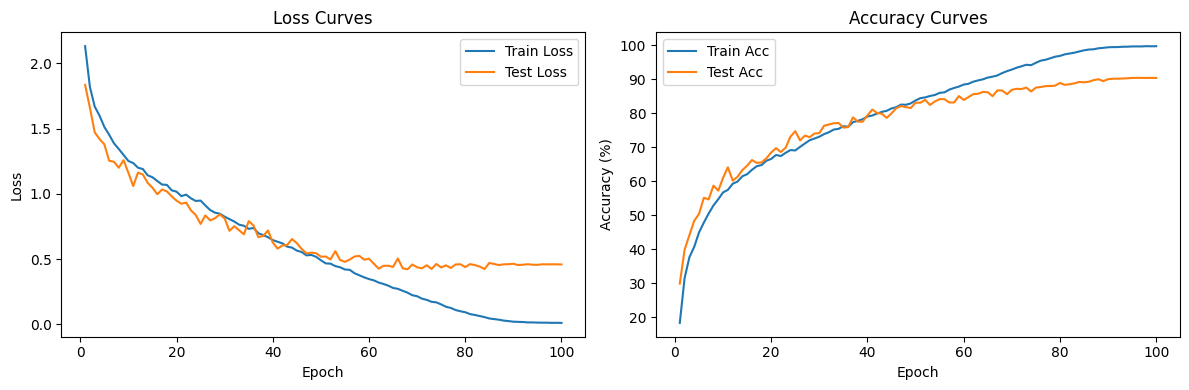

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs+1), train_losses, label='Train Loss')
plt.plot(range(1, num_epochs+1), test_losses, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss Curves')

plt.subplot(1, 2, 2)
plt.plot(range(1, num_epochs+1), train_accs, label='Train Acc')
plt.plot(range(1, num_epochs+1), test_accs, label='Test Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.title('Accuracy Curves')

plt.tight_layout()
plt.show()

### Results and Analysis / Results / Analysis

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [27]:
import gc

gc.collect()

489

### Model / Parameters / Output

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

|------|--------|----------|---------------------|


In [22]:
# Note on Model, Loss Function, Learning Rate, Initialize. Refer to the archived source for the detailed original comment.
# Note on Model. Refer to the archived source for the detailed original comment.
class ResidualBlock(nn.Module):
    """残差块：两个卷积 + BN + ReLU，可选下采样"""
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Shortcut 连接（若尺寸或通道变化，则用 1×1 卷积调整）
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        out = self.relu(out)
        return out

class ResNetCIFAR10(nn.Module):
    """自定义 CIFAR-10 残差网络"""
    def __init__(self):
        super().__init__()
        # 初始卷积层（不含 shortcut）
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(16)
        self.relu = nn.ReLU(inplace=True)

        # 三个残差块组
        self.layer1 = self._make_layer(16, 16, stride=1, blocks=2)   # 通道数不变，不降采样
        self.layer2 = self._make_layer(16, 32, stride=2, blocks=2)   # 通道数 16→32，尺寸减半
        self.layer3 = self._make_layer(32, 64, stride=2, blocks=2)   # 通道数 32→64，尺寸减半

        # 全局平均池化 + 全连接
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(64, 10)

    def _make_layer(self, in_channels, out_channels, stride, blocks):
        """创建一个包含多个残差块的层组"""
        layers = []
        layers.append(ResidualBlock(in_channels, out_channels, stride))
        for _ in range(1, blocks):
            layers.append(ResidualBlock(out_channels, out_channels, stride=1))
        return nn.Sequential(*layers)

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.avgpool(out)
        out = out.view(out.size(0), -1)
        out = self.fc(out)
        return out

### Parameters

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [23]:
model2 = ResNetCIFAR10().to(device)
total_params2 = sum(p.numel() for p in model2.parameters())
print(f"Total parameters: {total_params2:,}")

Total parameters: 175,258


In [24]:
for name, param in model2.named_parameters():
    print(f"{name:30} {str(param.shape):30} {str(param.dtype):10} {param.numel():>8} params    {param.requires_grad}")

conv1.weight                   torch.Size([16, 3, 3, 3])      torch.float32      432 params    True
bn1.weight                     torch.Size([16])               torch.float32       16 params    True
bn1.bias                       torch.Size([16])               torch.float32       16 params    True
layer1.0.conv1.weight          torch.Size([16, 16, 3, 3])     torch.float32     2304 params    True
layer1.0.bn1.weight            torch.Size([16])               torch.float32       16 params    True
layer1.0.bn1.bias              torch.Size([16])               torch.float32       16 params    True
layer1.0.conv2.weight          torch.Size([16, 16, 3, 3])     torch.float32     2304 params    True
layer1.0.bn2.weight            torch.Size([16])               torch.float32       16 params    True
layer1.0.bn2.bias              torch.Size([16])               torch.float32       16 params    True
layer1.1.conv1.weight          torch.Size([16, 16, 3, 3])     torch.float32     2304 params    True


In [25]:
print(f"Using device: {device}")

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model2.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)

# Note on Hyperparameters, Parameters. Refer to the archived source for the detailed original comment.
num_epochs = 100

Using device: cuda


In [26]:
print(f"Using device: {device}")

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model2.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)

# Note on Hyperparameters, Parameters. Refer to the archived source for the detailed original comment.
num_epochs = 5

Using device: cuda


### Model / Training

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [13]:
train_losses, test_losses = [], []
train_accs, test_accs = [], []

for epoch in range(num_epochs):
    # Note on Training. Refer to the archived source for the detailed original comment.
    model2.train()
    running_loss = 0.0
    correct, total = 0, 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)  # 移到 MPS
        
        optimizer.zero_grad()
        outputs = model2(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, pred = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (pred == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    # Note on Testing. Refer to the archived source for the detailed original comment.
    model2.eval()
    test_loss = 0.0
    correct, total = 0, 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model2(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item()
            _, pred = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (pred == labels).sum().item()

    test_loss = test_loss / len(test_loader)
    test_acc = 100 * correct / total
    test_losses.append(test_loss)
    test_accs.append(test_acc)

    # Note on Learning Rate. Refer to the archived source for the detailed original comment.
    scheduler.step()

    # 打印进度
    print(f'Epoch {epoch+1:3d}/{num_epochs} | Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | Test Loss: {test_loss:.4f} Acc: {test_acc:.2f}%')

Epoch   1/100 | Train Loss: 1.6387 Acc: 38.73% | Test Loss: 1.3774 Acc: 50.33%
Epoch   2/100 | Train Loss: 1.1743 Acc: 57.51% | Test Loss: 1.2578 Acc: 55.24%
Epoch   3/100 | Train Loss: 0.9355 Acc: 66.91% | Test Loss: 0.9565 Acc: 66.71%
Epoch   4/100 | Train Loss: 0.7920 Acc: 72.27% | Test Loss: 1.2062 Acc: 61.86%
Epoch   5/100 | Train Loss: 0.7227 Acc: 74.94% | Test Loss: 1.0767 Acc: 64.01%
Epoch   6/100 | Train Loss: 0.6747 Acc: 76.70% | Test Loss: 0.8722 Acc: 71.71%
Epoch   7/100 | Train Loss: 0.6427 Acc: 77.72% | Test Loss: 0.6757 Acc: 76.78%
Epoch   8/100 | Train Loss: 0.6074 Acc: 79.04% | Test Loss: 0.8440 Acc: 73.03%
Epoch   9/100 | Train Loss: 0.5944 Acc: 79.53% | Test Loss: 1.1799 Acc: 65.50%
Epoch  10/100 | Train Loss: 0.5810 Acc: 80.09% | Test Loss: 0.6777 Acc: 77.03%
Epoch  11/100 | Train Loss: 0.5631 Acc: 80.50% | Test Loss: 0.6596 Acc: 77.30%
Epoch  12/100 | Train Loss: 0.5566 Acc: 80.77% | Test Loss: 0.9988 Acc: 69.56%
Epoch  13/100 | Train Loss: 0.5524 Acc: 81.12% | Tes

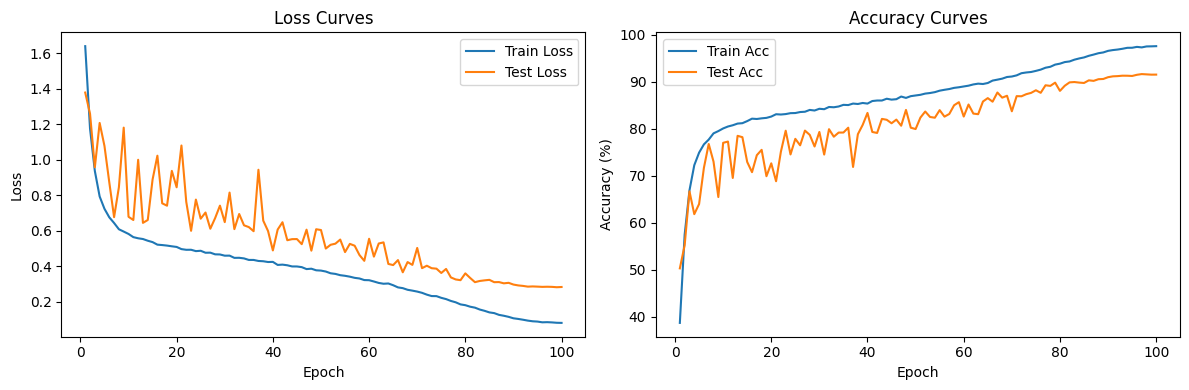

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs+1), train_losses, label='Train Loss')
plt.plot(range(1, num_epochs+1), test_losses, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss Curves')

plt.subplot(1, 2, 2)
plt.plot(range(1, num_epochs+1), train_accs, label='Train Acc')
plt.plot(range(1, num_epochs+1), test_accs, label='Test Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.title('Accuracy Curves')

plt.tight_layout()
plt.show()

### Results and Analysis / Results / Analysis

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Experiment / Results / Model

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [5]:
# Note on Settings. Refer to the archived source for the detailed original comment.
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# ---------- 设备 ----------
def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    elif torch.backends.mps.is_available():
        return torch.device("mps")
    else:
        return torch.device("cpu")

# Note on Data Loading, Load, Data. Refer to the archived source for the detailed original comment.
class CIFAR10FromNumpy(torch.utils.data.Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images.reshape(-1, 3, 32, 32)  # 确保是 (N, C, H, W)
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]          # 这是 (3,32,32) 的 NumPy 数组
        label = self.labels[idx]
        if self.transform:
            # Note on Input, Note. Refer to the archived source for the detailed original comment.
            # Note on Image. Refer to the archived source for the detailed original comment.
            from PIL import Image
            img = Image.fromarray((img.transpose(1,2,0) * 255).astype('uint8'))  # 转回 0~255 的 PIL 图像
            img = self.transform(img)
        return img, label

def get_data_loaders(batch_size, train_transform, test_transform,
                     num_workers=None, pin_memory=None):
    """
    根据设备自动配置 DataLoader 参数，也可手动指定覆盖。
    - CUDA: num_workers=4, pin_memory=True
    - MPS:  num_workers=0, pin_memory=False（避免多进程问题）
    - CPU:  num_workers=0, pin_memory=False
    """
    # 自动检测设备
    if torch.cuda.is_available():
        default_workers = 4
        default_pin = True
        print("🚀 CUDA detected: using num_workers=4, pin_memory=True")
    elif torch.backends.mps.is_available():
        default_workers = 0
        default_pin = False
        print("🍏 MPS detected: using num_workers=0, pin_memory=False")
    else:
        default_workers = 0
        default_pin = False
        print("💻 CPU mode: using num_workers=0, pin_memory=False")

    # Note on Use. Refer to the archived source for the detailed original comment.
    num_workers = num_workers if num_workers is not None else default_workers
    pin_memory = pin_memory if pin_memory is not None else default_pin

    # Note on Create. Refer to the archived source for the detailed original comment.
    train_dataset = CIFAR10FromNumpy(train_data, train_labels, transform=train_transform)
    test_dataset = CIFAR10FromNumpy(test_data, test_labels, transform=test_transform)

    # Note on Create. Refer to the archived source for the detailed original comment.
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=pin_memory
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=100,          # 测试集固定为 100
        shuffle=False,
        num_workers=num_workers,
        pin_memory=pin_memory
    )
    return train_loader, test_loader

In [6]:
# Note on Model. Refer to the archived source for the detailed original comment.
class ResidualBlock(nn.Module):
    """
    残差块（可配置激活函数、是否使用残差）
    - in_channels: 输入通道
    - out_channels: 输出通道
    - stride: 步长（用于下采样）
    - activation: 激活函数类型，支持 'relu', 'gelu', 'silu'
    - use_residual: 是否使用跳跃连接（若 False，则退化为普通卷积块）
    """
    def __init__(self, in_channels, out_channels, stride=1,
                 activation='relu', use_residual=True):
        super().__init__()
        # 选择激活函数
        if activation == 'relu':
            self.act = nn.ReLU(inplace=True)
        elif activation == 'gelu':
            self.act = nn.GELU()
        elif activation == 'silu':   # SiLU 即 Swish
            self.act = nn.SiLU()
        elif activation == 'mish':
            self.act = nn.Mish()   
        else:
            raise ValueError(f"Unsupported activation: {activation}")

        self.use_residual = use_residual

        # 第一个卷积：可能下采样
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)

        # 第二个卷积：保持尺寸
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        # 跳跃连接（仅当 use_residual=True 且尺寸/通道变化时）
        self.shortcut = nn.Sequential()
        if use_residual and (stride != 1 or in_channels != out_channels):
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = self.act(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.use_residual:
            out += self.shortcut(x)
        out = self.act(out)
        return out

In [7]:
class ResNetCIFAR10(nn.Module):
    """
    可配置的 CIFAR-10 残差网络
    - activation: 激活函数类型
    - use_residual: 是否全局使用残差连接
    - base_channels: 初始卷积后的通道数（后续层依次翻倍）
    - num_blocks: 每个层组中残差块的数量（层组数固定为3）
    """
    def __init__(self, activation='relu', use_residual=True,
                 base_channels=16, num_blocks=2):
        super().__init__()
        self.use_residual = use_residual

        # 选择激活函数（用于初始卷积后）
        if activation == 'relu':
            self.act = nn.ReLU(inplace=True)
        elif activation == 'gelu':
            self.act = nn.GELU()
        elif activation == 'silu':
            self.act = nn.SiLU()
        elif activation == 'mish':
            self.act = nn.Mish()   
        else:
            raise ValueError(f"Unsupported activation: {activation}")

        # 初始卷积层（无残差）
        self.conv1 = nn.Conv2d(3, base_channels, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(base_channels)

        # 三个层组，通道数依次翻倍，空间尺寸减半（通过 stride=2）
        self.layer1 = self._make_layer(base_channels, base_channels,
                                       stride=1, blocks=num_blocks,
                                       activation=activation)
        self.layer2 = self._make_layer(base_channels, base_channels * 2,
                                       stride=2, blocks=num_blocks,
                                       activation=activation)
        self.layer3 = self._make_layer(base_channels * 2, base_channels * 4,
                                       stride=2, blocks=num_blocks,
                                       activation=activation)

        # 全局平均池化 + 全连接
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(base_channels * 4, 10)

    def _make_layer(self, in_channels, out_channels, stride, blocks,
                    activation):
        """创建一个层组，包含多个残差块"""
        layers = []
        # 第一个块可能下采样
        layers.append(ResidualBlock(in_channels, out_channels, stride,
                                    activation, self.use_residual))
        # 后续块保持尺寸
        for _ in range(1, blocks):
            layers.append(ResidualBlock(out_channels, out_channels, 1,
                                        activation, self.use_residual))
        return nn.Sequential(*layers)

    def forward(self, x):
        out = self.act(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.avgpool(out)
        out = out.view(out.size(0), -1)
        out = self.fc(out)
        return out

In [8]:
# Note on Training. Refer to the archived source for the detailed original comment.
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss, correct, total = 0, 0, 0
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        _, pred = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (pred == labels).sum().item()
    return running_loss / len(loader), 100 * correct / total

def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item()
            _, pred = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (pred == labels).sum().item()
    return running_loss / len(loader), 100 * correct / total

def run_experiment(config):
    # 解包配置
    seed = config.get('seed', 42)
    set_seed(seed)
    device = get_device()
    print(f"Device: {device}")

    # Note on Data. Refer to the archived source for the detailed original comment.
    transform_train = transforms.Compose([
        transforms.RandomCrop(32, padding=4) if config.get('use_random_crop', True) else transforms.Lambda(lambda x: x),
        transforms.RandomHorizontalFlip() if config.get('use_horizontal_flip', True) else transforms.Lambda(lambda x: x),
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
    ])
    transform_test = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
    ])
    train_loader, test_loader = get_data_loaders(
        config['batch_size'],
        transform_train,
        transform_test,
        num_workers=config.get('num_workers', 4),
        pin_memory=(device.type == 'cuda')
    )

    # Note on Model. Refer to the archived source for the detailed original comment.
    model = ResNetCIFAR10(
        activation=config.get('activation', 'relu'),
        use_residual=config.get('use_residual', True),
        base_channels=config.get('base_channels', 16),
        num_blocks=config.get('num_blocks', 2)
    ).to(device)
    print(f"Total parameters: {sum(p.numel() for p in model.parameters())}")

    # Note on Loss Function. Refer to the archived source for the detailed original comment.
    criterion = nn.CrossEntropyLoss()

    # Note on Optimizer. Refer to the archived source for the detailed original comment.
    opt_name = config.get('optimizer', 'sgd')
    lr = config.get('lr', 0.1)
    if opt_name == 'sgd':
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=config.get('momentum', 0.9), weight_decay=config.get('weight_decay', 5e-4))
    elif opt_name == 'adam':
        optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=config.get('weight_decay', 0))
    elif opt_name == 'adamw':
        optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=config.get('weight_decay', 5e-4))
    else:
        raise ValueError(f"Unknown optimizer: {opt_name}")

    # Note on Learning Rate. Refer to the archived source for the detailed original comment.
    if config.get('use_cosine', True):
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config['num_epochs'])
    else:
        scheduler = None

    # 记录
    train_losses, test_losses = [], []
    train_accs, test_accs = [], []

    for epoch in range(1, config['num_epochs']+1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
        test_loss, test_acc = evaluate(model, test_loader, criterion, device)
        train_losses.append(train_loss); test_losses.append(test_loss)
        train_accs.append(train_acc); test_accs.append(test_acc)
        if scheduler:
            scheduler.step()
        print(f"Epoch {epoch:3d}/{config['num_epochs']} | Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | Test Loss: {test_loss:.4f} Acc: {test_acc:.2f}%")

    # Note on Save. Refer to the archived source for the detailed original comment.
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(train_losses, label='Train Loss')
    plt.plot(test_losses, label='Test Loss')
    plt.legend()
    plt.title('Loss')
    plt.subplot(1,2,2)
    plt.plot(train_accs, label='Train Acc')
    plt.plot(test_accs, label='Test Acc')
    plt.legend()
    plt.title('Accuracy')
    plt.savefig(config.get('plot_save_path', 'training_curves.png'))
    plt.show()

    # Note on Testing, Accuracy. Refer to the archived source for the detailed original comment.
    return test_accs[-1] if test_accs else None

### Experiment

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [9]:
# Note on Experiment. Refer to the archived source for the detailed original comment.
config_baseline = {
    'seed': 42,
    'batch_size': 128,
    'num_epochs': 60,
    'activation': 'relu',
    'use_residual': True,
    'base_channels': 16,
    'num_blocks': 2,
    'optimizer': 'sgd',
    'lr': 0.1,
    'weight_decay': 5e-4,
    'use_cosine': True,
    'use_random_crop': True,
    'use_horizontal_flip': True,
    'plot_save_path': 'baseline.png'
}

Device: cuda
🚀 CUDA detected: using num_workers=4, pin_memory=True
Total parameters: 175258
Epoch   1/60 | Train Loss: 1.6215 Acc: 39.11% | Test Loss: 1.3632 Acc: 49.48%
Epoch   2/60 | Train Loss: 1.1227 Acc: 59.38% | Test Loss: 1.1348 Acc: 59.20%
Epoch   3/60 | Train Loss: 0.9025 Acc: 67.75% | Test Loss: 1.0730 Acc: 64.77%
Epoch   4/60 | Train Loss: 0.7780 Acc: 72.75% | Test Loss: 0.8090 Acc: 72.38%
Epoch   5/60 | Train Loss: 0.7039 Acc: 75.66% | Test Loss: 1.0844 Acc: 64.12%
Epoch   6/60 | Train Loss: 0.6705 Acc: 76.65% | Test Loss: 0.7631 Acc: 74.47%
Epoch   7/60 | Train Loss: 0.6330 Acc: 77.98% | Test Loss: 0.9830 Acc: 69.61%
Epoch   8/60 | Train Loss: 0.6096 Acc: 78.76% | Test Loss: 0.7386 Acc: 74.97%
Epoch   9/60 | Train Loss: 0.5898 Acc: 79.77% | Test Loss: 1.0252 Acc: 68.52%
Epoch  10/60 | Train Loss: 0.5784 Acc: 80.08% | Test Loss: 0.7987 Acc: 74.57%
Epoch  11/60 | Train Loss: 0.5708 Acc: 80.31% | Test Loss: 0.9883 Acc: 70.01%
Epoch  12/60 | Train Loss: 0.5562 Acc: 80.85% | Te

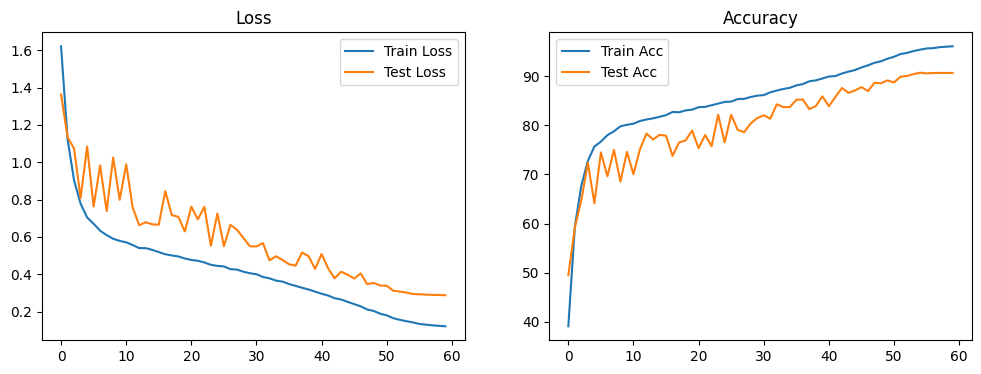

In [10]:
baseline_acc = run_experiment(config_baseline)

### Results and Analysis / Results / Analysis

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Gradient

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

$$
$$
$$
\text{SiLU}(x) = x \cdot \sigma(x),\sigma(x) = \frac{1}{1 + e^{-x}}
$$
$$
\text{Mish}(x) = x \cdot \tanh\bigl(\text{softplus}(x)\bigr),\text{softplus}(x) = \ln(1 + e^x)
$$


Device: cuda
🚀 CUDA detected: using num_workers=4, pin_memory=True
Total parameters: 175258
Epoch   1/60 | Train Loss: 1.6601 Acc: 37.09% | Test Loss: 1.5090 Acc: 43.62%
Epoch   2/60 | Train Loss: 1.1636 Acc: 57.76% | Test Loss: 1.1104 Acc: 60.75%
Epoch   3/60 | Train Loss: 0.9154 Acc: 67.31% | Test Loss: 1.1693 Acc: 62.97%
Epoch   4/60 | Train Loss: 0.7814 Acc: 72.81% | Test Loss: 0.7627 Acc: 73.83%
Epoch   5/60 | Train Loss: 0.6987 Acc: 75.68% | Test Loss: 0.7621 Acc: 73.25%
Epoch   6/60 | Train Loss: 0.6483 Acc: 77.57% | Test Loss: 0.6982 Acc: 75.97%
Epoch   7/60 | Train Loss: 0.6110 Acc: 78.84% | Test Loss: 0.6433 Acc: 77.88%
Epoch   8/60 | Train Loss: 0.5813 Acc: 79.99% | Test Loss: 0.8183 Acc: 74.56%
Epoch   9/60 | Train Loss: 0.5570 Acc: 80.85% | Test Loss: 0.9384 Acc: 71.48%
Epoch  10/60 | Train Loss: 0.5389 Acc: 81.35% | Test Loss: 0.5663 Acc: 80.60%
Epoch  11/60 | Train Loss: 0.5337 Acc: 81.61% | Test Loss: 0.6240 Acc: 78.63%
Epoch  12/60 | Train Loss: 0.5156 Acc: 82.31% | Te

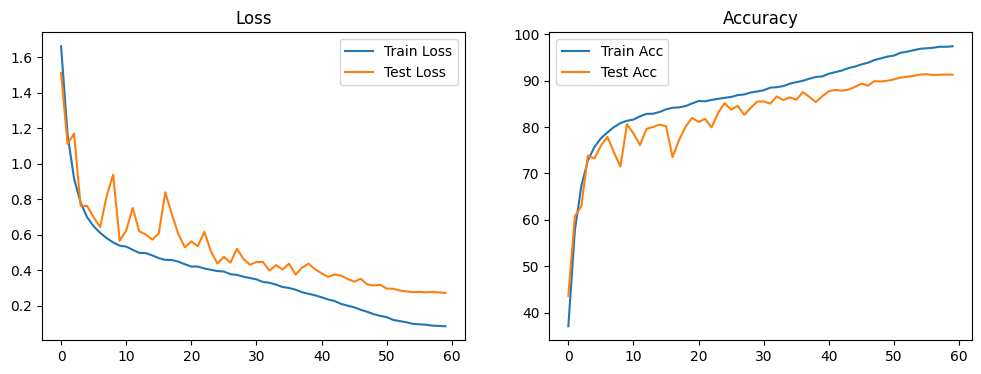

In [10]:
# 激活函数对比 (GELU)
config_gelu = config_baseline.copy()
config_gelu['activation'] = 'gelu'
config_gelu['plot_save_path'] = 'gelu.png'
gelu_acc = run_experiment(config_gelu)

Device: cuda
🚀 CUDA detected: using num_workers=4, pin_memory=True
Total parameters: 175258
Epoch   1/60 | Train Loss: 1.6309 Acc: 38.75% | Test Loss: 1.3601 Acc: 50.04%
Epoch   2/60 | Train Loss: 1.1516 Acc: 58.22% | Test Loss: 1.0833 Acc: 60.86%
Epoch   3/60 | Train Loss: 0.9325 Acc: 66.57% | Test Loss: 1.2377 Acc: 61.22%
Epoch   4/60 | Train Loss: 0.8007 Acc: 71.87% | Test Loss: 0.7842 Acc: 72.00%
Epoch   5/60 | Train Loss: 0.7154 Acc: 75.35% | Test Loss: 0.7401 Acc: 74.70%
Epoch   6/60 | Train Loss: 0.6689 Acc: 77.00% | Test Loss: 0.7891 Acc: 72.96%
Epoch   7/60 | Train Loss: 0.6303 Acc: 78.29% | Test Loss: 0.7140 Acc: 76.24%
Epoch   8/60 | Train Loss: 0.6062 Acc: 79.28% | Test Loss: 0.6148 Acc: 78.86%
Epoch   9/60 | Train Loss: 0.5853 Acc: 79.79% | Test Loss: 0.7865 Acc: 74.30%
Epoch  10/60 | Train Loss: 0.5609 Acc: 80.74% | Test Loss: 0.5825 Acc: 80.01%
Epoch  11/60 | Train Loss: 0.5477 Acc: 81.16% | Test Loss: 0.5935 Acc: 79.72%
Epoch  12/60 | Train Loss: 0.5343 Acc: 81.57% | Te

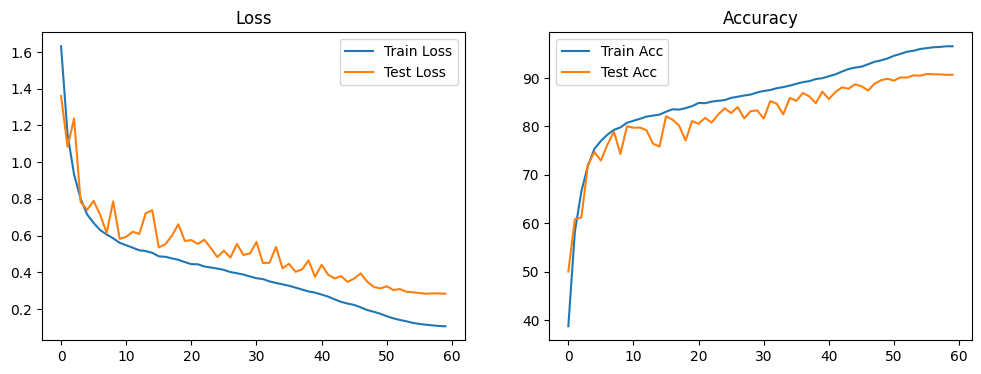

In [11]:
# 激活函数对比 (Swish （SiLU）)
config_silu = config_baseline.copy()
config_silu['activation'] = 'silu'
config_silu['plot_save_path'] = 'silu.png'
silu_acc = run_experiment(config_silu)

In [12]:
import gc
gc.collect()

15427

Device: cuda
🚀 CUDA detected: using num_workers=4, pin_memory=True
Total parameters: 175258
Epoch   1/60 | Train Loss: 1.6446 Acc: 37.66% | Test Loss: 1.6504 Acc: 41.27%
Epoch   2/60 | Train Loss: 1.1819 Acc: 57.24% | Test Loss: 1.0732 Acc: 61.84%
Epoch   3/60 | Train Loss: 0.9610 Acc: 65.84% | Test Loss: 1.2833 Acc: 60.07%
Epoch   4/60 | Train Loss: 0.8203 Acc: 71.25% | Test Loss: 0.8145 Acc: 71.63%
Epoch   5/60 | Train Loss: 0.7365 Acc: 74.43% | Test Loss: 0.7683 Acc: 73.71%
Epoch   6/60 | Train Loss: 0.6815 Acc: 76.47% | Test Loss: 0.6978 Acc: 76.26%
Epoch   7/60 | Train Loss: 0.6375 Acc: 77.91% | Test Loss: 0.6596 Acc: 77.69%
Epoch   8/60 | Train Loss: 0.6102 Acc: 78.98% | Test Loss: 0.6757 Acc: 76.97%
Epoch   9/60 | Train Loss: 0.5908 Acc: 79.62% | Test Loss: 0.7850 Acc: 74.32%
Epoch  10/60 | Train Loss: 0.5618 Acc: 80.71% | Test Loss: 0.6281 Acc: 78.93%
Epoch  11/60 | Train Loss: 0.5552 Acc: 81.03% | Test Loss: 0.6304 Acc: 78.37%
Epoch  12/60 | Train Loss: 0.5380 Acc: 81.40% | Te

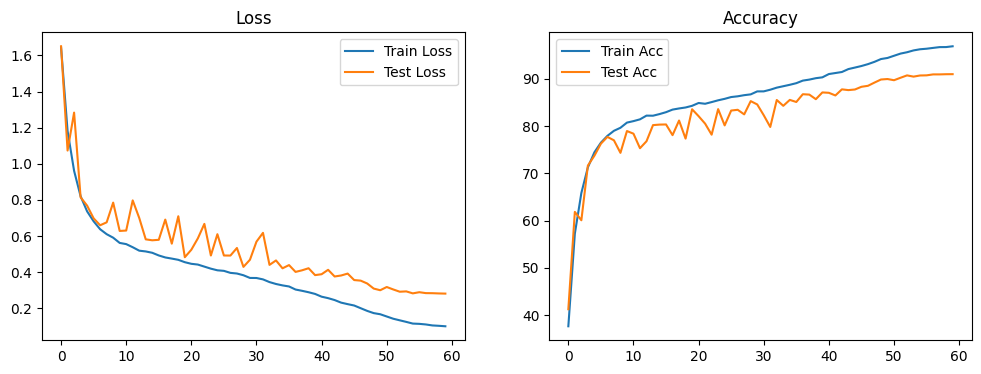

In [13]:
# 激活函数对比 (Mish)
config_mish = config_baseline.copy()
config_mish['activation'] = 'mish'
config_mish['plot_save_path'] = 'mish.png'
mish_acc = run_experiment(config_mish)

### Results and Analysis / Results / Analysis

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

GELU (91.28%) > Mish (90.95%) > SiLU (90.66%) ≈ ReLU (90.62%)


### Loss Function / Hyperparameters / Learning Rate

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


Device: cuda
🚀 CUDA detected: using num_workers=4, pin_memory=True
Total parameters: 175258
Epoch   1/60 | Train Loss: 1.4431 Acc: 46.85% | Test Loss: 1.2635 Acc: 55.00%
Epoch   2/60 | Train Loss: 1.0419 Acc: 62.87% | Test Loss: 1.1463 Acc: 60.58%
Epoch   3/60 | Train Loss: 0.8838 Acc: 68.42% | Test Loss: 1.0335 Acc: 65.54%
Epoch   4/60 | Train Loss: 0.7808 Acc: 72.44% | Test Loss: 0.9573 Acc: 67.32%
Epoch   5/60 | Train Loss: 0.7094 Acc: 75.31% | Test Loss: 0.8202 Acc: 72.29%
Epoch   6/60 | Train Loss: 0.6587 Acc: 76.94% | Test Loss: 0.7222 Acc: 75.64%
Epoch   7/60 | Train Loss: 0.6133 Acc: 78.63% | Test Loss: 0.6624 Acc: 77.55%
Epoch   8/60 | Train Loss: 0.5769 Acc: 80.08% | Test Loss: 0.6658 Acc: 77.15%
Epoch   9/60 | Train Loss: 0.5500 Acc: 81.07% | Test Loss: 0.6535 Acc: 78.70%
Epoch  10/60 | Train Loss: 0.5267 Acc: 81.78% | Test Loss: 0.5631 Acc: 80.99%
Epoch  11/60 | Train Loss: 0.5092 Acc: 82.48% | Test Loss: 0.6137 Acc: 79.84%
Epoch  12/60 | Train Loss: 0.4879 Acc: 83.23% | Te

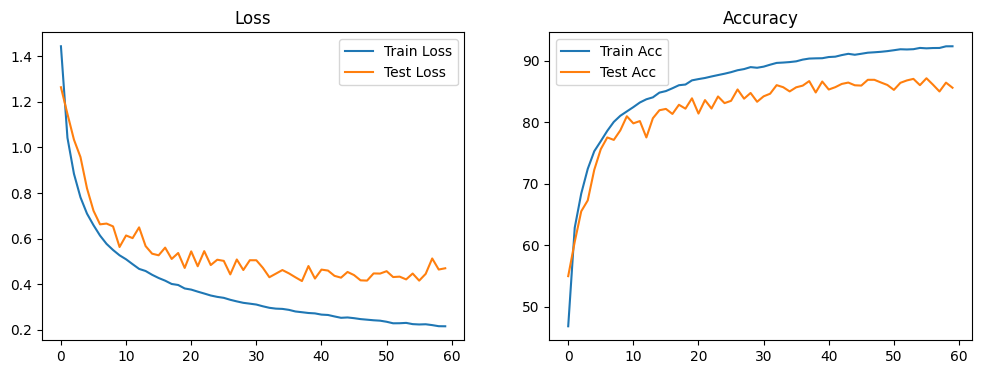

In [10]:
# Note on Optimizer. Refer to the archived source for the detailed original comment.
config_adam = config_baseline.copy()
config_adam['optimizer'] = 'adam'
config_adam['lr'] = 0.001
config_adam['use_cosine'] = False
config_adam['weight_decay'] = 1e-4
config_adam['plot_save_path'] = 'adam.png'
adam_acc = run_experiment(config_adam)

Device: cuda
🚀 CUDA detected: using num_workers=4, pin_memory=True
Total parameters: 175258
Epoch   1/60 | Train Loss: 1.4399 Acc: 46.92% | Test Loss: 1.1912 Acc: 57.01%
Epoch   2/60 | Train Loss: 1.0359 Acc: 63.12% | Test Loss: 1.2208 Acc: 58.80%
Epoch   3/60 | Train Loss: 0.8774 Acc: 68.78% | Test Loss: 1.2697 Acc: 61.09%
Epoch   4/60 | Train Loss: 0.7713 Acc: 72.91% | Test Loss: 0.8383 Acc: 70.92%
Epoch   5/60 | Train Loss: 0.6980 Acc: 75.57% | Test Loss: 0.7794 Acc: 72.71%
Epoch   6/60 | Train Loss: 0.6504 Acc: 77.20% | Test Loss: 0.6752 Acc: 76.91%
Epoch   7/60 | Train Loss: 0.6036 Acc: 79.05% | Test Loss: 0.6368 Acc: 78.39%
Epoch   8/60 | Train Loss: 0.5667 Acc: 80.56% | Test Loss: 0.6141 Acc: 79.50%
Epoch   9/60 | Train Loss: 0.5400 Acc: 81.20% | Test Loss: 0.6151 Acc: 79.30%
Epoch  10/60 | Train Loss: 0.5134 Acc: 82.19% | Test Loss: 0.5758 Acc: 81.12%
Epoch  11/60 | Train Loss: 0.4937 Acc: 82.83% | Test Loss: 0.5407 Acc: 81.54%
Epoch  12/60 | Train Loss: 0.4755 Acc: 83.52% | Te

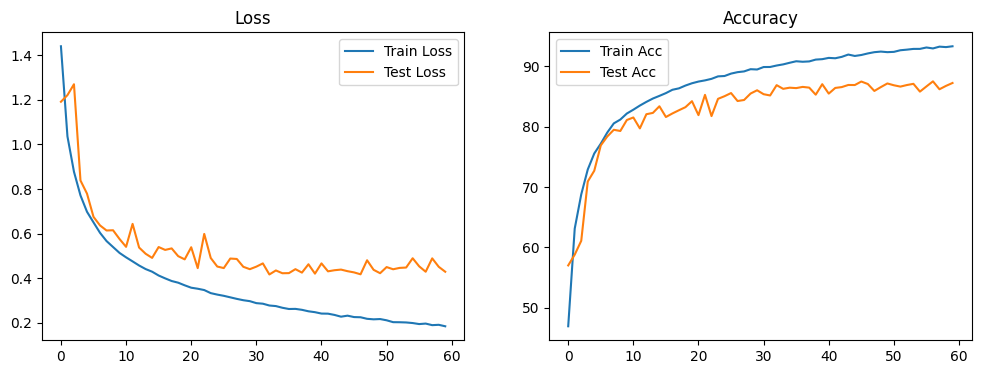

In [13]:
# Note on Optimizer. Refer to the archived source for the detailed original comment.
config_adamw = config_baseline.copy()
config_adamw['optimizer'] = 'adamw'
config_adamw['lr'] = 0.001
config_adamw['use_cosine'] = False
config_adamw['weight_decay'] = 1e-4
config_adamw['plot_save_path'] = 'adamw.png'
adamw_acc = run_experiment(config_adamw)

### Analysis / Model / Testing

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Question / Gradient

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


Device: cuda
🚀 CUDA detected: using num_workers=4, pin_memory=True
Total parameters: 172506
Epoch   1/60 | Train Loss: 1.7310 Acc: 33.76% | Test Loss: 1.6731 Acc: 40.57%
Epoch   2/60 | Train Loss: 1.3177 Acc: 52.04% | Test Loss: 1.6853 Acc: 45.93%
Epoch   3/60 | Train Loss: 1.0654 Acc: 61.79% | Test Loss: 1.3281 Acc: 55.61%
Epoch   4/60 | Train Loss: 0.9273 Acc: 67.15% | Test Loss: 0.9874 Acc: 66.53%
Epoch   5/60 | Train Loss: 0.8274 Acc: 71.19% | Test Loss: 1.0537 Acc: 65.87%
Epoch   6/60 | Train Loss: 0.7575 Acc: 73.67% | Test Loss: 1.0547 Acc: 65.93%
Epoch   7/60 | Train Loss: 0.7242 Acc: 74.87% | Test Loss: 0.7467 Acc: 74.56%
Epoch   8/60 | Train Loss: 0.6862 Acc: 76.32% | Test Loss: 1.0842 Acc: 66.52%
Epoch   9/60 | Train Loss: 0.6683 Acc: 76.69% | Test Loss: 0.7608 Acc: 74.18%
Epoch  10/60 | Train Loss: 0.6383 Acc: 78.00% | Test Loss: 0.9612 Acc: 69.71%
Epoch  11/60 | Train Loss: 0.6272 Acc: 78.34% | Test Loss: 0.8278 Acc: 71.57%
Epoch  12/60 | Train Loss: 0.6128 Acc: 78.95% | Te

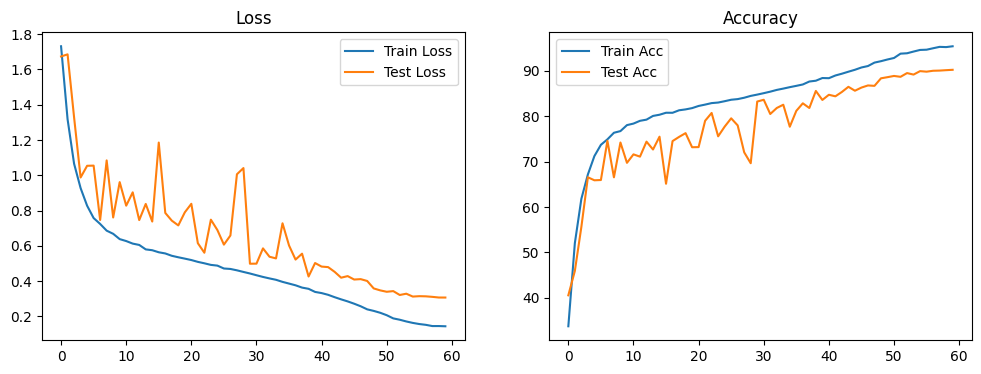

In [14]:
# 残差连接对比 (去掉残差)
config_no_res = config_baseline.copy()
config_no_res['use_residual'] = False
config_no_res['plot_save_path'] = 'no_res.png'
no_res_acc = run_experiment(config_no_res)

### Experiment / Results and Analysis / Results

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Model / Testing / Image

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


Device: cuda
🚀 CUDA detected: using num_workers=4, pin_memory=True
Total parameters: 175258
Epoch   1/60 | Train Loss: 1.5062 Acc: 43.76% | Test Loss: 1.6855 Acc: 41.89%
Epoch   2/60 | Train Loss: 1.0121 Acc: 63.69% | Test Loss: 1.0830 Acc: 61.62%
Epoch   3/60 | Train Loss: 0.8073 Acc: 71.25% | Test Loss: 1.0427 Acc: 64.54%
Epoch   4/60 | Train Loss: 0.7004 Acc: 75.43% | Test Loss: 0.7791 Acc: 73.37%
Epoch   5/60 | Train Loss: 0.6238 Acc: 78.13% | Test Loss: 0.7852 Acc: 72.93%
Epoch   6/60 | Train Loss: 0.5823 Acc: 79.57% | Test Loss: 0.7516 Acc: 73.81%
Epoch   7/60 | Train Loss: 0.5436 Acc: 81.09% | Test Loss: 0.6840 Acc: 76.70%
Epoch   8/60 | Train Loss: 0.5127 Acc: 82.20% | Test Loss: 0.6775 Acc: 77.09%
Epoch   9/60 | Train Loss: 0.4944 Acc: 82.92% | Test Loss: 0.7115 Acc: 76.00%
Epoch  10/60 | Train Loss: 0.4681 Acc: 83.73% | Test Loss: 0.7886 Acc: 74.79%
Epoch  11/60 | Train Loss: 0.4543 Acc: 84.24% | Test Loss: 0.6358 Acc: 78.39%
Epoch  12/60 | Train Loss: 0.4398 Acc: 84.69% | Te

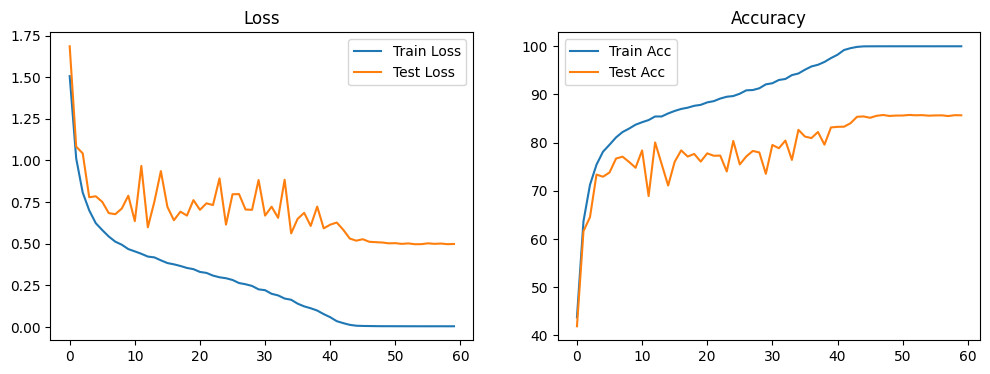

In [28]:
# Note on Data. Refer to the archived source for the detailed original comment.
config_no_aug = config_baseline.copy()
config_no_aug['use_random_crop'] = False
config_no_aug['use_horizontal_flip'] = False
config_no_aug['plot_save_path'] = 'no_aug.png'

no_aug_acc = run_experiment(config_no_aug)

Device: cuda
🚀 CUDA detected: using num_workers=4, pin_memory=True
Total parameters: 175258
Epoch   1/60 | Train Loss: 1.5193 Acc: 43.20% | Test Loss: 1.4295 Acc: 46.86%
Epoch   2/60 | Train Loss: 1.0072 Acc: 63.83% | Test Loss: 1.2311 Acc: 57.85%
Epoch   3/60 | Train Loss: 0.8017 Acc: 71.86% | Test Loss: 0.8108 Acc: 71.80%
Epoch   4/60 | Train Loss: 0.6996 Acc: 75.64% | Test Loss: 0.7735 Acc: 73.37%
Epoch   5/60 | Train Loss: 0.6355 Acc: 77.99% | Test Loss: 0.8400 Acc: 70.24%
Epoch   6/60 | Train Loss: 0.5976 Acc: 79.25% | Test Loss: 0.7214 Acc: 75.09%
Epoch   7/60 | Train Loss: 0.5607 Acc: 80.53% | Test Loss: 0.6829 Acc: 77.30%
Epoch   8/60 | Train Loss: 0.5427 Acc: 81.31% | Test Loss: 0.8729 Acc: 71.09%
Epoch   9/60 | Train Loss: 0.5272 Acc: 81.87% | Test Loss: 0.6008 Acc: 78.91%
Epoch  10/60 | Train Loss: 0.5112 Acc: 82.41% | Test Loss: 0.6350 Acc: 78.49%
Epoch  11/60 | Train Loss: 0.4936 Acc: 83.10% | Test Loss: 0.6565 Acc: 77.53%
Epoch  12/60 | Train Loss: 0.4835 Acc: 83.41% | Te

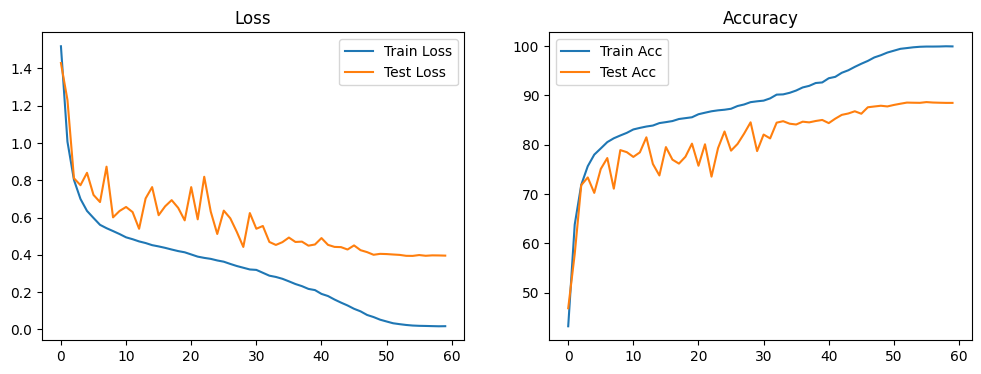

In [29]:
# Note on Data. Refer to the archived source for the detailed original comment.
config_hflip = config_baseline.copy()
config_hflip['use_random_crop'] = False
config_hflip['use_horizontal_flip'] = True
config_hflip['plot_save_path'] = 'hflip.png'

hflip_acc = run_experiment(config_hflip)

Device: cuda
🚀 CUDA detected: using num_workers=4, pin_memory=True
Total parameters: 175258
Epoch   1/60 | Train Loss: 1.6215 Acc: 39.11% | Test Loss: 1.3632 Acc: 49.48%
Epoch   2/60 | Train Loss: 1.1227 Acc: 59.38% | Test Loss: 1.1348 Acc: 59.20%
Epoch   3/60 | Train Loss: 0.9025 Acc: 67.75% | Test Loss: 1.0730 Acc: 64.77%
Epoch   4/60 | Train Loss: 0.7780 Acc: 72.75% | Test Loss: 0.8090 Acc: 72.38%
Epoch   5/60 | Train Loss: 0.7039 Acc: 75.66% | Test Loss: 1.0844 Acc: 64.12%
Epoch   6/60 | Train Loss: 0.6705 Acc: 76.65% | Test Loss: 0.7631 Acc: 74.47%
Epoch   7/60 | Train Loss: 0.6330 Acc: 77.98% | Test Loss: 0.9830 Acc: 69.61%
Epoch   8/60 | Train Loss: 0.6096 Acc: 78.76% | Test Loss: 0.7386 Acc: 74.97%
Epoch   9/60 | Train Loss: 0.5898 Acc: 79.77% | Test Loss: 1.0252 Acc: 68.52%
Epoch  10/60 | Train Loss: 0.5784 Acc: 80.08% | Test Loss: 0.7987 Acc: 74.57%
Epoch  11/60 | Train Loss: 0.5708 Acc: 80.31% | Test Loss: 0.9883 Acc: 70.01%
Epoch  12/60 | Train Loss: 0.5562 Acc: 80.85% | Te

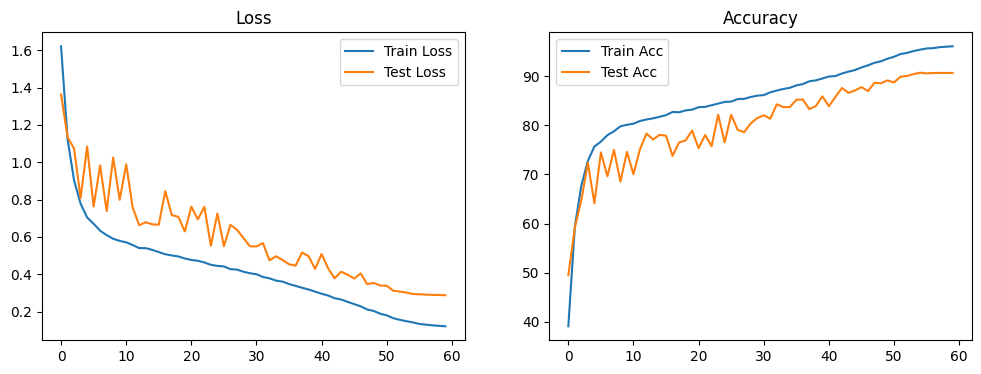

In [30]:
# Note on Data. Refer to the archived source for the detailed original comment.
config_full_aug = config_baseline.copy()  # 默认 use_random_crop=True, use_horizontal_flip=True
config_full_aug['plot_save_path'] = 'full_aug.png'

full_aug_acc = run_experiment(config_full_aug)

### Results and Analysis / Results / Analysis

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Experiment / Network Architecture / Parameters

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

config_baseline = {
'base_channels': 16,
'num_blocks': 2,
}


Device: cuda
🚀 CUDA detected: using num_workers=4, pin_memory=True
Total parameters: 174274
Epoch   1/60 | Train Loss: 1.5903 Acc: 40.71% | Test Loss: 1.5718 Acc: 47.01%
Epoch   2/60 | Train Loss: 1.1673 Acc: 58.13% | Test Loss: 1.0915 Acc: 61.01%
Epoch   3/60 | Train Loss: 0.9766 Acc: 65.41% | Test Loss: 1.0893 Acc: 61.83%
Epoch   4/60 | Train Loss: 0.8530 Acc: 70.03% | Test Loss: 1.0393 Acc: 64.53%
Epoch   5/60 | Train Loss: 0.7758 Acc: 72.87% | Test Loss: 1.0393 Acc: 64.88%
Epoch   6/60 | Train Loss: 0.7263 Acc: 74.86% | Test Loss: 0.7933 Acc: 72.97%
Epoch   7/60 | Train Loss: 0.6832 Acc: 76.38% | Test Loss: 1.0645 Acc: 65.00%
Epoch   8/60 | Train Loss: 0.6566 Acc: 77.32% | Test Loss: 0.7968 Acc: 72.55%
Epoch   9/60 | Train Loss: 0.6333 Acc: 78.08% | Test Loss: 0.9353 Acc: 68.12%
Epoch  10/60 | Train Loss: 0.6233 Acc: 78.51% | Test Loss: 0.9718 Acc: 68.42%
Epoch  11/60 | Train Loss: 0.6109 Acc: 78.77% | Test Loss: 0.8357 Acc: 72.19%
Epoch  12/60 | Train Loss: 0.5980 Acc: 79.54% | Te

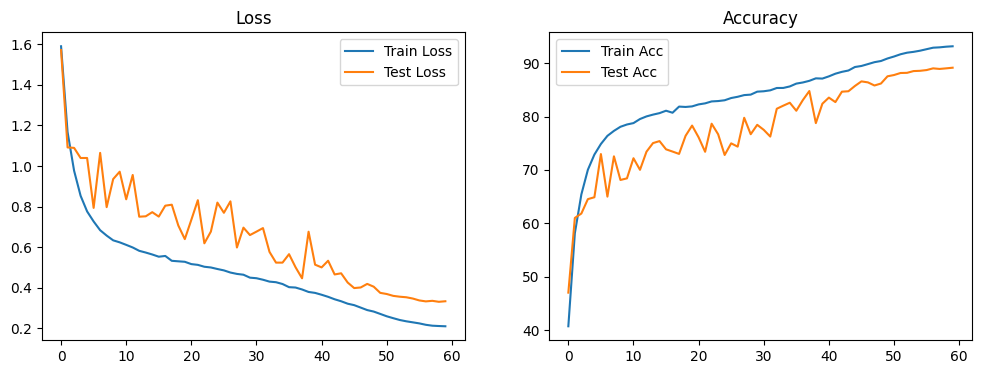

In [33]:
# Note on Parameters. Refer to the archived source for the detailed original comment.
config_wide_shallow = config_baseline.copy()
config_wide_shallow['base_channels'] = 24
config_wide_shallow['num_blocks'] = 1   # 减少层数
config_wide_shallow['plot_save_path'] = 'wide_shallow.png'
wide_shallow_acc = run_experiment(config_wide_shallow)

Device: cuda
🚀 CUDA detected: using num_workers=4, pin_memory=True
Total parameters: 180281
Epoch   1/60 | Train Loss: 1.6654 Acc: 36.93% | Test Loss: 1.4838 Acc: 46.12%
Epoch   2/60 | Train Loss: 1.2031 Acc: 56.21% | Test Loss: 1.1040 Acc: 60.40%
Epoch   3/60 | Train Loss: 1.0017 Acc: 64.21% | Test Loss: 1.1685 Acc: 61.76%
Epoch   4/60 | Train Loss: 0.8692 Acc: 69.55% | Test Loss: 1.3431 Acc: 58.44%
Epoch   5/60 | Train Loss: 0.7758 Acc: 72.90% | Test Loss: 0.8169 Acc: 71.89%
Epoch   6/60 | Train Loss: 0.7197 Acc: 75.22% | Test Loss: 0.9845 Acc: 67.96%
Epoch   7/60 | Train Loss: 0.6832 Acc: 76.35% | Test Loss: 0.8100 Acc: 72.08%
Epoch   8/60 | Train Loss: 0.6527 Acc: 77.41% | Test Loss: 0.8058 Acc: 71.95%
Epoch   9/60 | Train Loss: 0.6264 Acc: 78.25% | Test Loss: 0.7817 Acc: 73.59%
Epoch  10/60 | Train Loss: 0.6037 Acc: 79.10% | Test Loss: 0.7156 Acc: 75.56%
Epoch  11/60 | Train Loss: 0.5895 Acc: 79.70% | Test Loss: 0.8930 Acc: 71.73%
Epoch  12/60 | Train Loss: 0.5698 Acc: 80.32% | Te

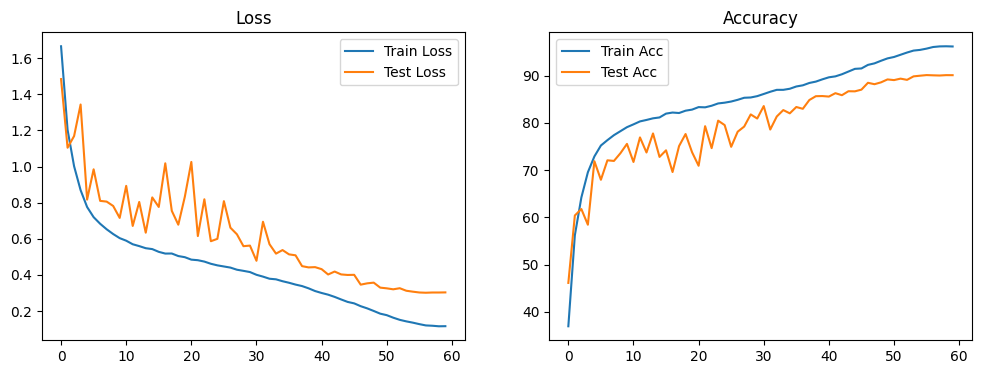

In [34]:
# Note on Parameters. Refer to the archived source for the detailed original comment.
config_narrow_deep = config_baseline.copy()
config_narrow_deep['base_channels'] = 13
config_narrow_deep['num_blocks'] = 3
config_narrow_deep['plot_save_path'] = 'narrow_deep.png'
narrow_deep_acc = run_experiment(config_narrow_deep)

### Results and Analysis / Results / Analysis

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Results

This cell documents the pytorch in practice experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


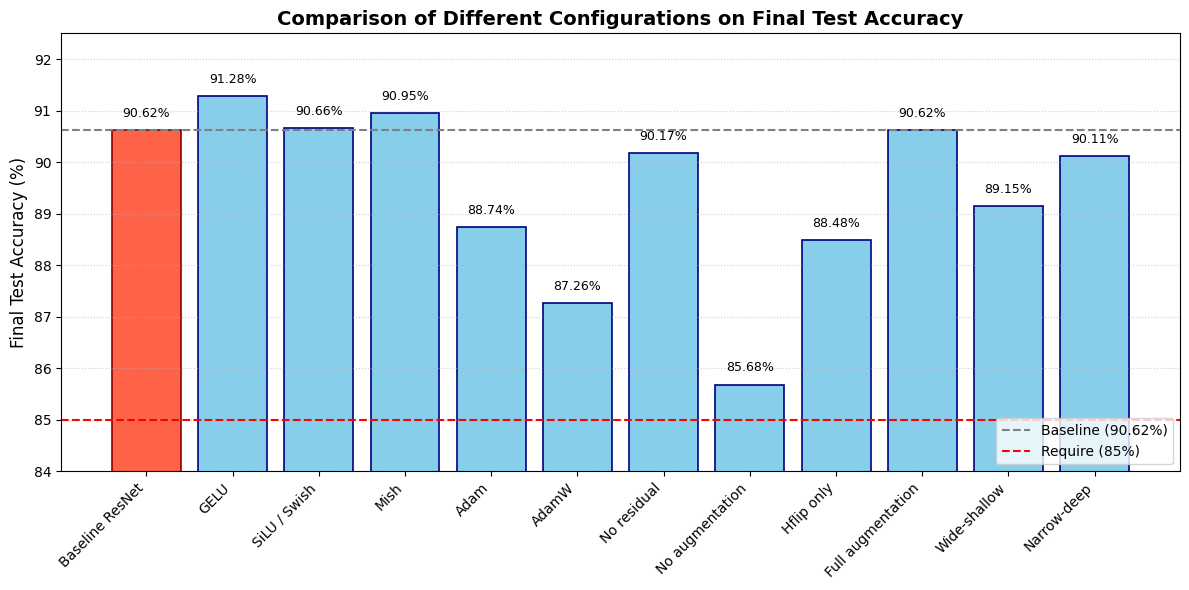

In [4]:
# Note on Results. Refer to the archived source for the detailed original comment.
data = {
    "Baseline ResNet": 90.62,
    "GELU": 91.28,
    "SiLU / Swish": 90.66,
    "Mish": 90.95,
    "Adam": 88.74,
    "AdamW": 87.26,
    "No residual": 90.17,
    "No augmentation": 85.68,
    "Hflip only": 88.48,
    "Full augmentation": 90.62,
    "Wide-shallow": 89.15,
    "Narrow-deep": 90.11
}

categories = list(data.keys())
accuracies = list(data.values())

# Note on Create. Refer to the archived source for the detailed original comment.
plt.figure(figsize=(12, 6))
bars = plt.bar(categories, accuracies, color='skyblue', edgecolor='navy', linewidth=1.2)

# 高亮 Baseline 柱子
baseline_idx = categories.index("Baseline ResNet")
bars[baseline_idx].set_color('tomato')
bars[baseline_idx].set_edgecolor('darkred')

# 添加数值标签
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             f'{acc:.2f}%', ha='center', va='bottom', fontsize=9)

# Note on References. Refer to the archived source for the detailed original comment.
plt.axhline(y=90.62, color='gray', linestyle='--', linewidth=1.5, label='Baseline (90.62%)')
plt.axhline(y=85, color='red', linestyle='--', linewidth=1.5, label='Require (85%)')

# 图表装饰
plt.ylabel('Final Test Accuracy (%)', fontsize=12)
plt.title('Comparison of Different Configurations on Final Test Accuracy', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(np.arange(84, 93, 1))
plt.ylim(84, 92.5)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()